# Module 5: E-Commerce Product Recommendation System
### Item-Based Collaborative Filtering & Cosine Similarity
### Senior Data Scientist & ML Engineering Portfolio
---
### Objectives:
1. **Interaction Matrix**: Construct high-dimensional customer-product interaction matrices from 395k+ clean transactional lines.
2. **Mathematical Intuition of Item-Based Collaborative Filtering**:
   $$\text{Cosine Similarity}(i, j) = \frac{\mathbf{u}_i \cdot \mathbf{u}_j}{\|\mathbf{u}_i\|_2 \|\mathbf{u}_j\|_2}$$
3. **Item-to-Item Cross-Selling**: Implement "Frequently Bought Together" recommendations for catalog product detail pages.
4. **Personalized User Recommendations**: Aggregate affinity vectors across a customer's lifetime purchase history and filter out already-purchased SKUs.
5. **Cold-Start Handling**: Implement high-velocity bestseller fallback for new visitors.


In [1]:
import sys
from pathlib import Path
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')


## 1. Initializing the Recommender Engine
We invoke `src.models.recommender.ProductRecommender` to load verified customer transactions and construct the catalog.


In [2]:
from src.models.recommender import ProductRecommender

recommender = ProductRecommender(data_path=Path('../data/processed/online_retail_customer_centric.csv'), min_interactions=5)
recommender.load_and_preprocess()
recommender.build_similarity_matrix()
print(f"Similarity matrix shape: {recommender.similarity_df.shape}")


[Recommender] Loaded 395,418 transactions across 4,333 customers.
[Recommender] Active candidate catalog: 3,182 SKUs (min 5 purchases).
[Recommender] Computing pairwise Cosine Similarity matrix for 3182 SKUs...


[Recommender] Serialized Item Similarity Matrix to: /Users/aryangupta/Desktop/e-commerce/models/item_similarity_matrix.joblib
[Recommender] Serialized Product Catalog to: /Users/aryangupta/Desktop/e-commerce/models/product_catalog.joblib
Similarity matrix shape: (3182, 3182)


## 2. Item-to-Item Cross-Sell ("Frequently Bought Together")
When a customer views the **Regency Cakestand 3 Tier (StockCode: 22423)**, what complementary items should we showcase on the product page?


In [3]:
sample_sku = "22423"
meta = recommender.product_catalog[sample_sku]
print(f"Base Product: [{sample_sku}] {meta['Description']} (£{meta['UnitPrice']})")

similar_items = recommender.recommend_similar_items(sample_sku, top_n=5)
pd.DataFrame(similar_items)


Base Product: [22423] Regency Cakestand 3 Tier (£12.75)


,StockCode,Description,UnitPrice,SimilarityScore
0,22699,Roses Regency Teacup And Saucer,2.95,0.5258
1,22697,Green Regency Teacup And Saucer,2.95,0.5086
2,22698,Pink Regency Teacup And Saucer,2.95,0.4886
3,23245,Set Of 3 Regency Cake Tins,4.95,0.4668
4,23173,Regency Teapot Roses,9.95,0.4535


## 3. High-Affinity Cross-Sell Heatmap
Visualizing pairwise similarity scores between the base item and top recommendations.


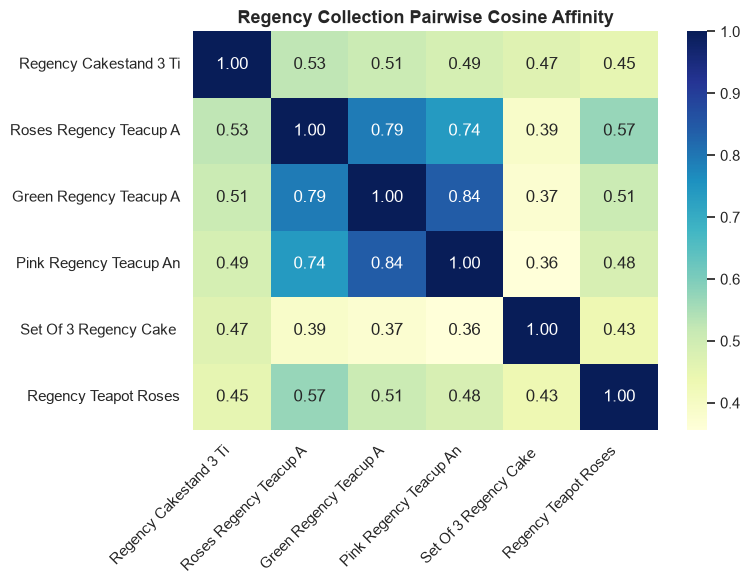

In [4]:
top_skus = [sample_sku] + [item['StockCode'] for item in similar_items]
sub_sim = recommender.similarity_df.loc[top_skus, top_skus]
labels = [recommender.product_catalog[s]['Description'][:22] for s in top_skus]

plt.figure(figsize=(8, 6))
sns.heatmap(sub_sim, annot=True, cmap='YlGnBu', xticklabels=labels, yticklabels=labels, fmt='.2f')
plt.title('Regency Collection Pairwise Cosine Affinity', fontsize=13, weight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 4. User-Personalized Recommendations
For an existing customer (e.g. `17850`), we aggregate their past basket vectors and recommend novel, unpurchased items with the highest cumulative affinity.


In [5]:
customer_id = "17850"
past_purchases = recommender.customer_baskets.get(customer_id, set())
print(f"Customer {customer_id} has previously purchased {len(past_purchases)} distinct products.")

user_recs = recommender.recommend_for_customer(customer_id, top_n=5)
pd.DataFrame(user_recs)


Customer 17850 has previously purchased 21 distinct products.


,StockCode,Description,UnitPrice,AggregatedAffinityScore
0,21733,Red Hanging Heart T-Light Holder,2.95,4.0736
1,23355,Hot Water Bottle Keep Calm,4.95,3.9029
2,22865,Hand Warmer Owl Design,2.10,3.8968
3,22470,Heart Of Wicker Large,2.95,3.8756
4,22469,Heart Of Wicker Small,1.65,3.7388


## 5. Cold-Start Problem & Popularity Fallback
For anonymous visitors or new accounts with zero prior interactions, the system defaults to high-velocity catalog staples.


In [6]:
cold_start_recs = recommender.get_cold_start_recommendations(top_n=5)
pd.DataFrame(cold_start_recs)


,StockCode,Description,UnitPrice,Strategy
0,85123A,White Hanging Heart T-Light Holder,2.95,Cold-Start (Top Platform Bestseller)
1,22423,Regency Cakestand 3 Tier,12.75,Cold-Start (Top Platform Bestseller)
2,85099B,Jumbo Bag Red Retrospot,2.08,Cold-Start (Top Platform Bestseller)
3,47566,Party Bunting,4.95,Cold-Start (Top Platform Bestseller)
4,84879,Assorted Colour Bird Ornament,1.69,Cold-Start (Top Platform Bestseller)
